# Лабораторная работа № 1. Линейная регрессия

#### Выполнил
Федосов Д.А. М8О-312БВ-24

#### Цель работы

Исследовать данные о заявках на кредит и построить модель линейной регрессии для предсказания показателя риска `RiskScore`.

## Загрузка данных

В работе используются три файла:

- `train.csv` — обучающие данные с известным значением `RiskScore`;
- `test.csv` — данные для итогового предсказания;
- `ex.csv` — пример файла для отправки результата на Kaggle.

Загрузим таблицы и посмотрим на их размеры и содержимое.

In [6]:
import pandas as pd

In [7]:
trainData = pd.read_csv("train.csv")
testData = pd.read_csv("test.csv")
exampleData = pd.read_csv("ex.csv")

## Исследование данных

### Проверка на наличие пропущенных значений

Изучим типы признаков и проверим, есть ли в данных пропущенные значения.

In [8]:
trainData.info()

<class 'pandas.DataFrame'>
RangeIndex: 11017 entries, 0 to 11016
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             10487 non-null  str    
 1   Age                         10487 non-null  float64
 2   AnnualIncome                10487 non-null  float64
 3   CreditScore                 9986 non-null   float64
 4   LoanAmount                  9986 non-null   float64
 5   LoanDuration                10487 non-null  float64
 6   MaritalStatus               10487 non-null  str    
 7   NumberOfDependents          10487 non-null  float64
 8   HomeOwnershipStatus         10487 non-null  str    
 9   MonthlyDebtPayments         9986 non-null   float64
 10  CreditCardUtilizationRate   10487 non-null  float64
 11  NumberOfOpenCreditLines     10487 non-null  float64
 12  NumberOfCreditInquiries     10487 non-null  float64
 13  DebtToIncomeRatio           10487 non-null

In [10]:
missingCounts = trainData.isna().sum()

print("Количество пропусков:")
print(missingCounts[missingCounts > 0])

Количество пропусков:
ApplicationDate                530
Age                            530
AnnualIncome                   530
CreditScore                   1031
LoanAmount                    1031
LoanDuration                   530
MaritalStatus                  530
NumberOfDependents             530
HomeOwnershipStatus            530
MonthlyDebtPayments           1031
CreditCardUtilizationRate      530
NumberOfOpenCreditLines        530
NumberOfCreditInquiries        530
DebtToIncomeRatio              530
BankruptcyHistory             1031
LoanPurpose                   1031
PreviousLoanDefaults           530
PaymentHistory                 530
LengthOfCreditHistory          530
SavingsAccountBalance          530
CheckingAccountBalance        1031
TotalAssets                   1031
TotalLiabilities               530
MonthlyIncome                  530
UtilityBillsPaymentHistory     530
JobTenure                      530
EmploymentStatus               530
EducationLevel                 53

В обучающей выборке обнаружены полностью пустые строки.
Они не содержат ни признаков, ни целевого значения, поэтому удалим их.

In [11]:
emptyCount = trainData.isna().all(axis=1).sum()

trainData = trainData.dropna(how="all").reset_index(drop=True)

print("Удалено полностью пустых строк:", emptyCount)
print("Осталось строк:", len(trainData))
print("Пропусков в RiskScore:", trainData["RiskScore"].isna().sum())

Удалено полностью пустых строк: 530
Осталось строк: 10487
Пропусков в RiskScore: 0


### Распределение целевой переменной

Изучим значения `RiskScore` и построим гистограмму.
Это поможет понять, какие значения риска встречаются чаще, а также заметить возможные крайние значения.

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64


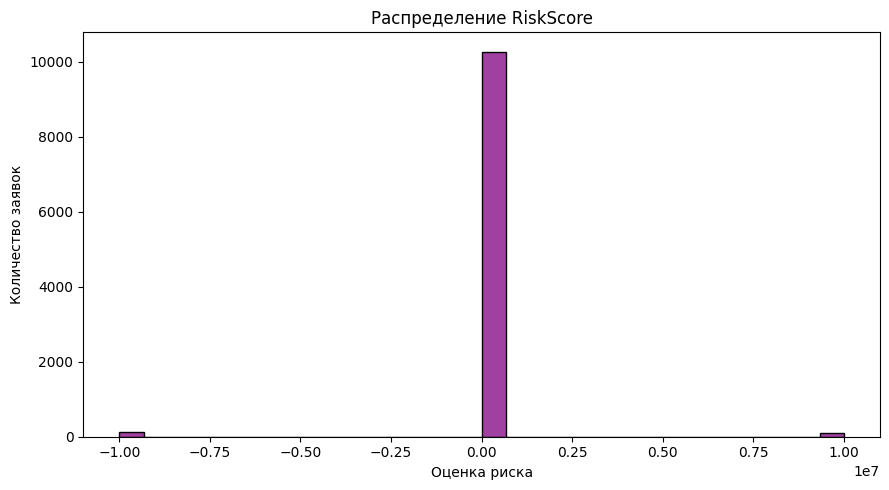

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

print(trainData["RiskScore"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(data=trainData, x="RiskScore", bins=30, color='purple')

plt.title("Распределение RiskScore")
plt.xlabel("Оценка риска")
plt.ylabel("Количество заявок")

plt.tight_layout()
plt.show()

В столбце `RiskScore` обнаружены крайне большие по модулю значения. Из-за них распределение основной части данных плохо видно на общей гистограмме. Для дополнительной визуализации рассмотрим диапазон между 5-м и 95-м перцентилями.

Нижняя граница: 25.980871265302326
Верхняя граница: 76.46135679815963
Строк на графике: 9437


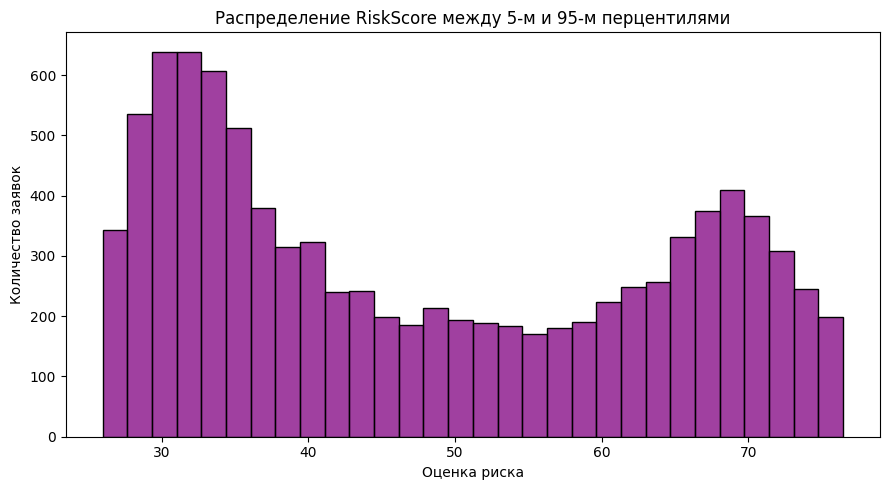

In [33]:
lowLimit = trainData["RiskScore"].quantile(0.05)
highLimit = trainData["RiskScore"].quantile(0.95)

plotData = trainData[
    (trainData["RiskScore"] >= lowLimit)
    & (trainData["RiskScore"] <= highLimit)
]

print("Нижняя граница:", lowLimit)
print("Верхняя граница:", highLimit)
print("Строк на графике:", len(plotData))

plt.figure(figsize=(9, 5))

sns.histplot(data=plotData, x="RiskScore", bins=30, color='purple')

plt.title("Распределение RiskScore между 5-м и 95-м перцентилями")
plt.xlabel("Оценка риска")
plt.ylabel("Количество заявок")

plt.tight_layout()
plt.show()

Основная часть рассматриваемых значений `RiskScore` находится примерно в диапазоне от 26 до 76. На гистограмме видны два пика: около 30–35 и около 65–70.

In [21]:
extremeScores = trainData[trainData["RiskScore"].abs() > 100]

print("Количество крайних значений:", len(extremeScores))
print("\nКрайние значения RiskScore:")
print(extremeScores["RiskScore"].value_counts())

Количество крайних значений: 215

Крайние значения RiskScore:
RiskScore
-9999999.0     121
 10000000.0     94
Name: count, dtype: int64


Обнаружено 215 значений `RiskScore` с модулем больше 100:
121 значение равно −9 999 999, ещё 94 значения равны 10 000 000.
Остальные значения находятся примерно в диапазоне от 10 до 100.

In [22]:
cleanData = trainData[~trainData["RiskScore"].isin([-9999999.0, 10000000.0])].copy()

print("Строк до очистки:", len(trainData))
print("Строк после очистки:", len(cleanData))

Строк до очистки: 10487
Строк после очистки: 10272


### Связь признаков с оценкой риска

Рассмотрим связь возраста и годового дохода с целевой переменной
`RiskScore` с помощью диаграмм рассеяния.

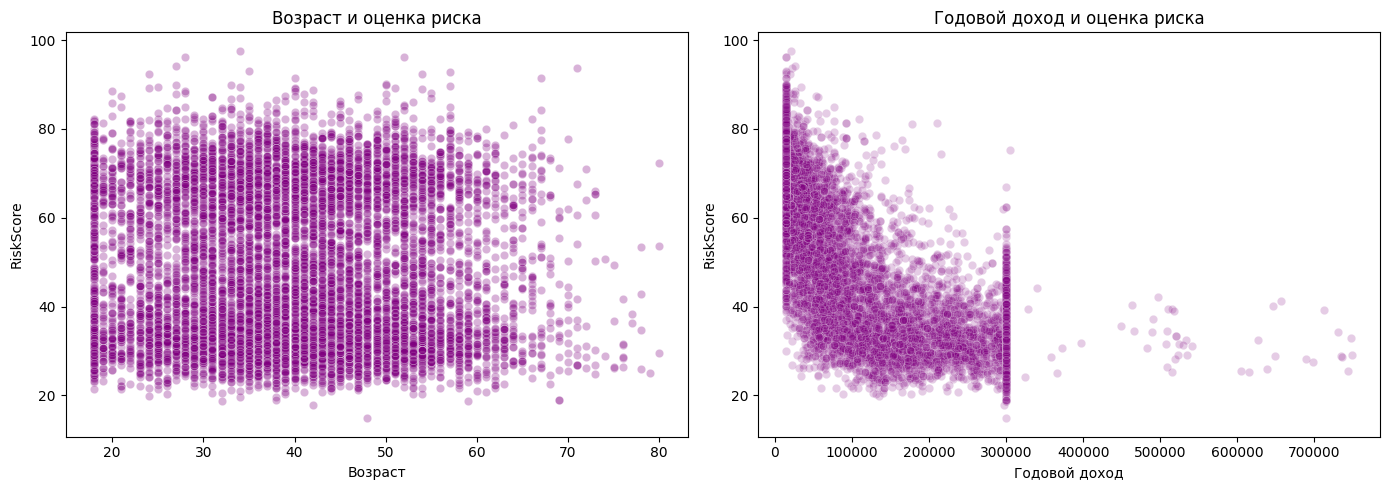

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=cleanData,
    x="Age",
    y="RiskScore",
    c='purple',
    alpha=0.3,
    ax=axes[0]
)

axes[0].set_title("Возраст и оценка риска")
axes[0].set_xlabel("Возраст")
axes[0].set_ylabel("RiskScore")

sns.scatterplot(
    data=cleanData,
    x="AnnualIncome",
    y="RiskScore",
    c='purple',
    alpha=0.2,
    ax=axes[1]
)

axes[1].set_title("Годовой доход и оценка риска")
axes[1].set_xlabel("Годовой доход")
axes[1].set_ylabel("RiskScore")

plt.tight_layout()
plt.show()

На диаграмме возраста и `RiskScore` явной зависимости не видно: при одинаковом возрасте встречаются разные оценки риска.

На диаграмме дохода заметно, что при больших значениях годового дохода высокие оценки риска встречаются реже. Также присутствуют отдельные наблюдения с очень высоким доходом.

### Матрица корреляций

Построим матрицу корреляций Пирсона для числовых признаков.
Она поможет заметить линейные связи между признаками и `RiskScore`,
а также связи признаков между собой.

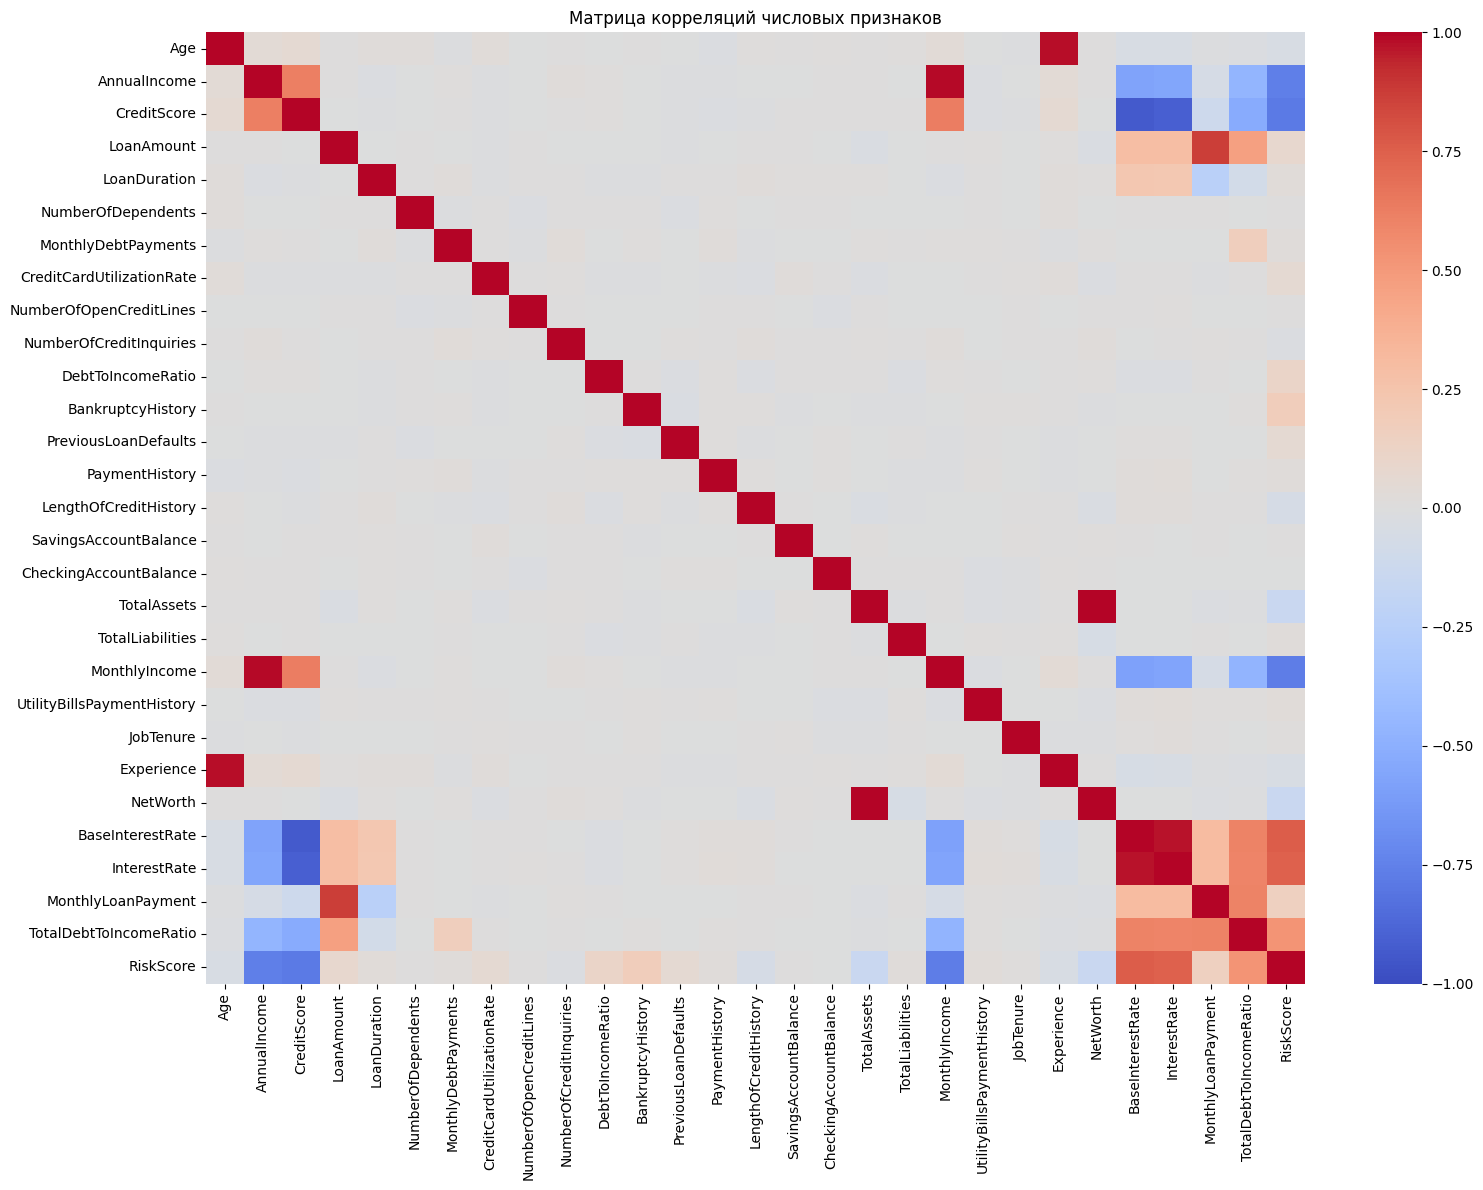

In [ ]:
numericData = cleanData.select_dtypes(include="number")

correlationMatrix = numericData.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlationMatrix,
    cmap="cool",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Матрица корреляций числовых признаков")
plt.tight_layout()
plt.show()